# Analyse exploratoire des données — Telco Customer Churn

## 1. Contexte et objectifs

Ce notebook explore le jeu de données **Telco Customer Churn** dans le cadre du projet d'analyse de survie avec Deep Learning.

L'objectif est de comprendre les caractéristiques des clients, d'étudier les facteurs associés à la résiliation (*churn*) et d'analyser la durée d'abonnement.

### Convention de survie
- `duration` : durée d'abonnement en mois (`tenure`).
- `event = 1` : résiliation observée (`Churn = Yes`).
- `event = 0` : client non résilié pendant la période observée (`Churn = No`), donc observation censurée à droite.

Le notebook réalise le chargement, le contrôle qualité, l'analyse descriptive, l'étude du churn et l'analyse de Kaplan-Meier / Log-Rank.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

RANDOM_SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", palette="deep")

print(f"pandas : {pd.__version__}")
print(f"NumPy : {np.__version__}")

pandas : 2.3.3
NumPy : 1.26.4


## 2. Chargement des données

Le fichier attendu est `data/raw/telco-customer-churn.csv`. Le notebook recherche automatiquement la racine du projet à partir du répertoire courant.

In [2]:
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]

PROJECT_ROOT = next(
    (
        path
        for path in candidates
        if (path / "data" / "raw" / "telco-customer-churn.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Dataset introuvable depuis {cwd}. "
        "Placez telco-customer-churn.csv dans data/raw/."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "telco-customer-churn.csv"
df_raw = pd.read_csv(DATA_PATH)

print(f"Répertoire courant : {cwd}")
print(f"Racine du projet : {PROJECT_ROOT}")
print(f"Dimensions : {df_raw.shape}")
display(df_raw.head())

Répertoire courant : D:\Projects\survival-churn-deeplearning\notebooks
Racine du projet : D:\Projects\survival-churn-deeplearning
Dimensions : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Compréhension générale des données

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
display(df_raw.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(f"Nombre de lignes : {len(df_raw)}")
print(f"Nombre de colonnes : {df_raw.shape[1]}")
print(f"Clients uniques : {df_raw['customerID'].nunique()}")
print(f"Lignes dupliquées : {df_raw.duplicated().sum()}")
print(f"Identifiants dupliqués : {df_raw['customerID'].duplicated().sum()}")

Nombre de lignes : 7043
Nombre de colonnes : 21
Clients uniques : 7043
Lignes dupliquées : 0
Identifiants dupliqués : 0


## 4. Qualité des données

On vérifie les valeurs manquantes, les chaînes vides et les types de données. Dans ce dataset, `TotalCharges` est importée comme texte car certaines valeurs sont vides.

In [6]:
missing = df_raw.isna().sum().sort_values(ascending=False)
blank_strings = (
    df_raw.select_dtypes(include="object")
    .apply(lambda column: column.str.strip().eq("").sum())
    .sort_values(ascending=False)
)

display(pd.DataFrame({
    "valeurs_manquantes": missing,
    "chaines_vides": blank_strings.reindex(missing.index, fill_value=0),
}))

,valeurs_manquantes,chaines_vides
customerID,0,0
DeviceProtection,0,0
TotalCharges,0,11
MonthlyCharges,0,0
PaymentMethod,0,0
PaperlessBilling,0,0
Contract,0,0
StreamingMovies,0,0
StreamingTV,0,0
TechSupport,0,0


In [7]:
df_quality = df_raw.copy()
df_quality["TotalCharges"] = pd.to_numeric(
    df_quality["TotalCharges"].replace(r"^\\s*$", np.nan, regex=True),
    errors="coerce",
)

missing_total = df_quality["TotalCharges"].isna()
print(f"TotalCharges manquants après conversion : {missing_total.sum()}")
display(
    df_quality.loc[
        missing_total,
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"],
    ]
)

TotalCharges manquants après conversion : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [8]:
zero_tenure_missing = df_quality["TotalCharges"].isna() & df_quality["tenure"].eq(0)
print(f"Valeurs manquantes avec tenure = 0 : {zero_tenure_missing.sum()}")
print(
    "Toutes les lignes concernées ont tenure = 0 :",
    df_quality.loc[missing_total, "tenure"].eq(0).all(),
)
print(
    "Toutes les lignes concernées ont Churn = No :",
    df_quality.loc[missing_total, "Churn"].eq("No").all(),
)

Valeurs manquantes avec tenure = 0 : 11
Toutes les lignes concernées ont tenure = 0 : True
Toutes les lignes concernées ont Churn = No : True


### Traitement retenu

Les 11 valeurs vides de `TotalCharges` correspondent à des clients dont `tenure = 0` : aucun mois d'abonnement facturé n'a encore été enregistré. On les remplace donc par `0.0`. Cette décision est spécifique à ces observations et ne consiste pas à imputer arbitrairement toutes les valeurs manquantes.

In [9]:
df_clean = df_quality.copy()
df_clean.loc[zero_tenure_missing, "TotalCharges"] = 0.0

if df_clean["TotalCharges"].isna().any():
    raise ValueError("Des valeurs TotalCharges restent manquantes.")

df_clean["TotalCharges"] = df_clean["TotalCharges"].astype(float)
print("Valeurs manquantes restantes :", int(df_clean.isna().sum().sum()))

Valeurs manquantes restantes : 0


## 5. Analyse descriptive des variables numériques

In [10]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df_clean[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


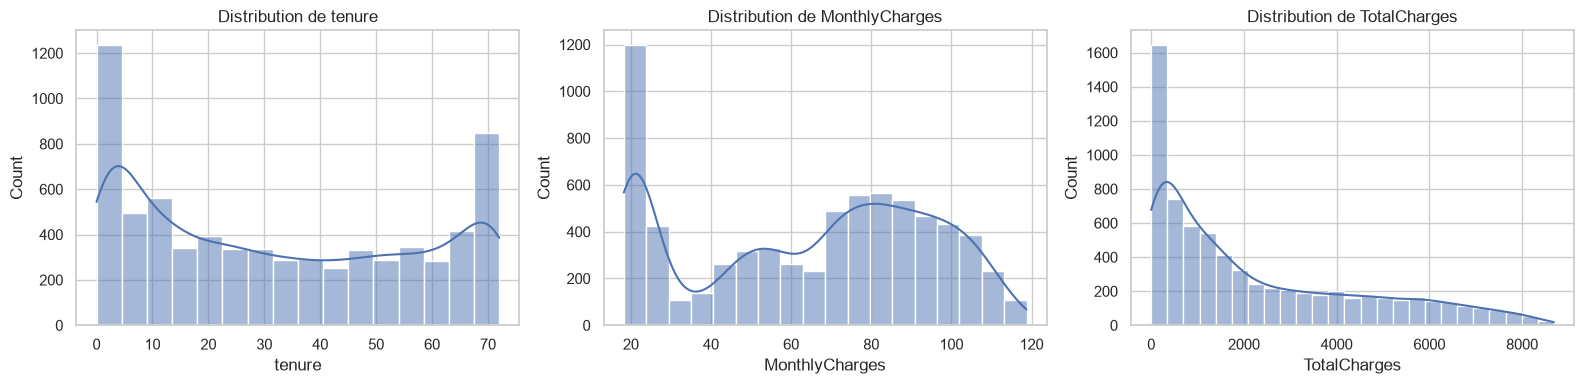

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, numeric_cols, strict=False):
    sns.histplot(data=df_clean, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")

plt.tight_layout()
plt.show()

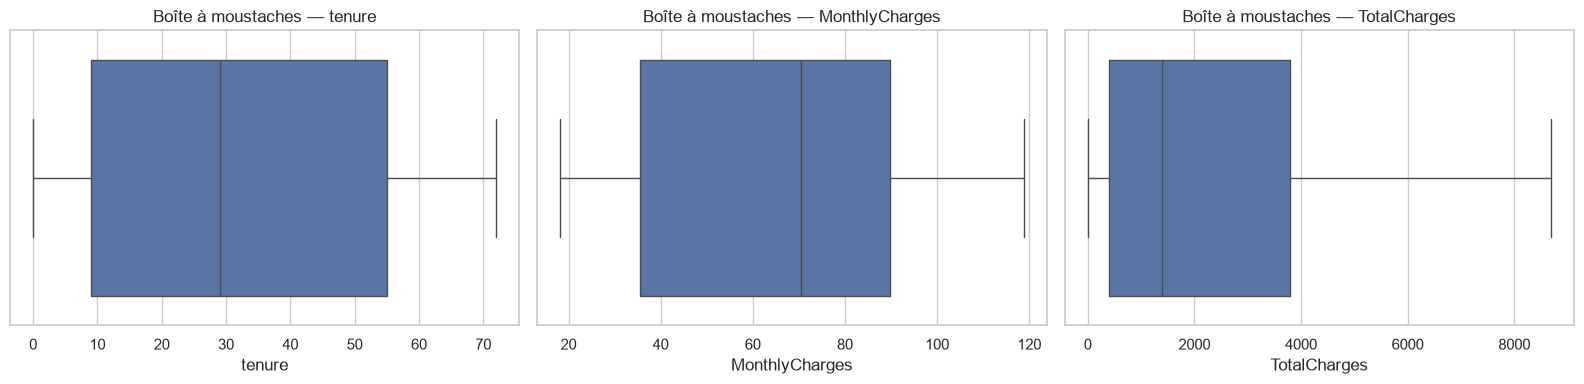

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, numeric_cols, strict=False):
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Boîte à moustaches — {col}")

plt.tight_layout()
plt.show()

## 6. Répartition du churn et censure

In [13]:
churn_counts = df_clean["Churn"].value_counts()
churn_rates = df_clean["Churn"].value_counts(normalize=True).mul(100)

display(pd.DataFrame({
    "effectif": churn_counts,
    "pourcentage": churn_rates.round(2),
}))

,effectif,pourcentage
Churn,,
No,5174,73.46
Yes,1869,26.54


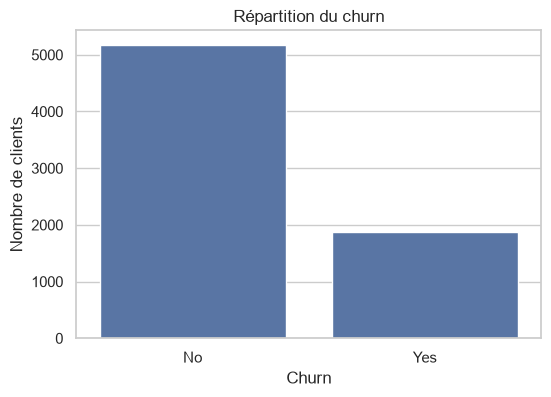

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="Churn", order=["No", "Yes"])
plt.title("Répartition du churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.show()

In [15]:
duration = df_clean["tenure"].to_numpy(dtype=float)
event = df_clean["Churn"].eq("Yes").astype(int).to_numpy()

print(f"Nombre de clients : {len(df_clean)}")
print(f"Événements observés : {event.sum()}")
print(f"Observations censurées : {(event == 0).sum()}")
print(f"Taux d'événements : {event.mean():.2%}")

Nombre de clients : 7043
Événements observés : 1869
Observations censurées : 5174
Taux d'événements : 26.54%


**Interprétation :** `Churn = No` signifie que la résiliation n'a pas été observée pendant la période disponible. En analyse de survie, ces clients sont considérés comme censurés à droite ; cela ne prouve pas qu'ils ne résilieront jamais.

## 7. Durée d'abonnement et churn

In [16]:
display(
    df_clean.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(index={"No": "Censuré (No)", "Yes": "Churn observé (Yes)"})
)

,count,mean,median,min,max
Churn,,,,,
Censuré (No),5174,37.569965,38.0,0,72
Churn observé (Yes),1869,17.979133,10.0,1,72


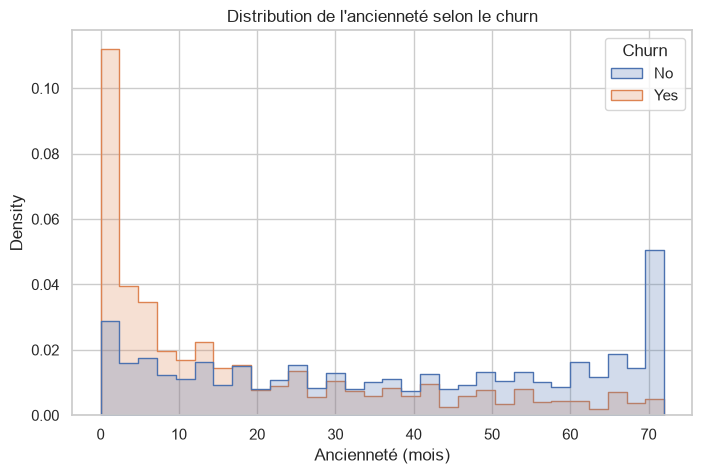

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
)
plt.title("Distribution de l'ancienneté selon le churn")
plt.xlabel("Ancienneté (mois)")
plt.show()

## 8. Analyse du churn selon les variables catégorielles

In [18]:
categorical_cols = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
    "SeniorCitizen",
]

for col in categorical_cols:
    rates = (
        df_clean.groupby(col, observed=False)["Churn"]
        .apply(lambda values: values.eq("Yes").mean() * 100)
        .sort_values(ascending=False)
    )
    print(f"\nTaux de churn selon {col} (%)")
    display(rates.round(2).to_frame("taux_churn_pct"))


Taux de churn selon Contract (%)


,taux_churn_pct
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Taux de churn selon PaymentMethod (%)


,taux_churn_pct
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



Taux de churn selon InternetService (%)


,taux_churn_pct
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


... (4 outputs left out)


Taux de churn selon PaperlessBilling (%)


,taux_churn_pct
PaperlessBilling,
Yes,33.57
No,16.33



Taux de churn selon SeniorCitizen (%)


,taux_churn_pct
SeniorCitizen,
1,41.68
0,23.61


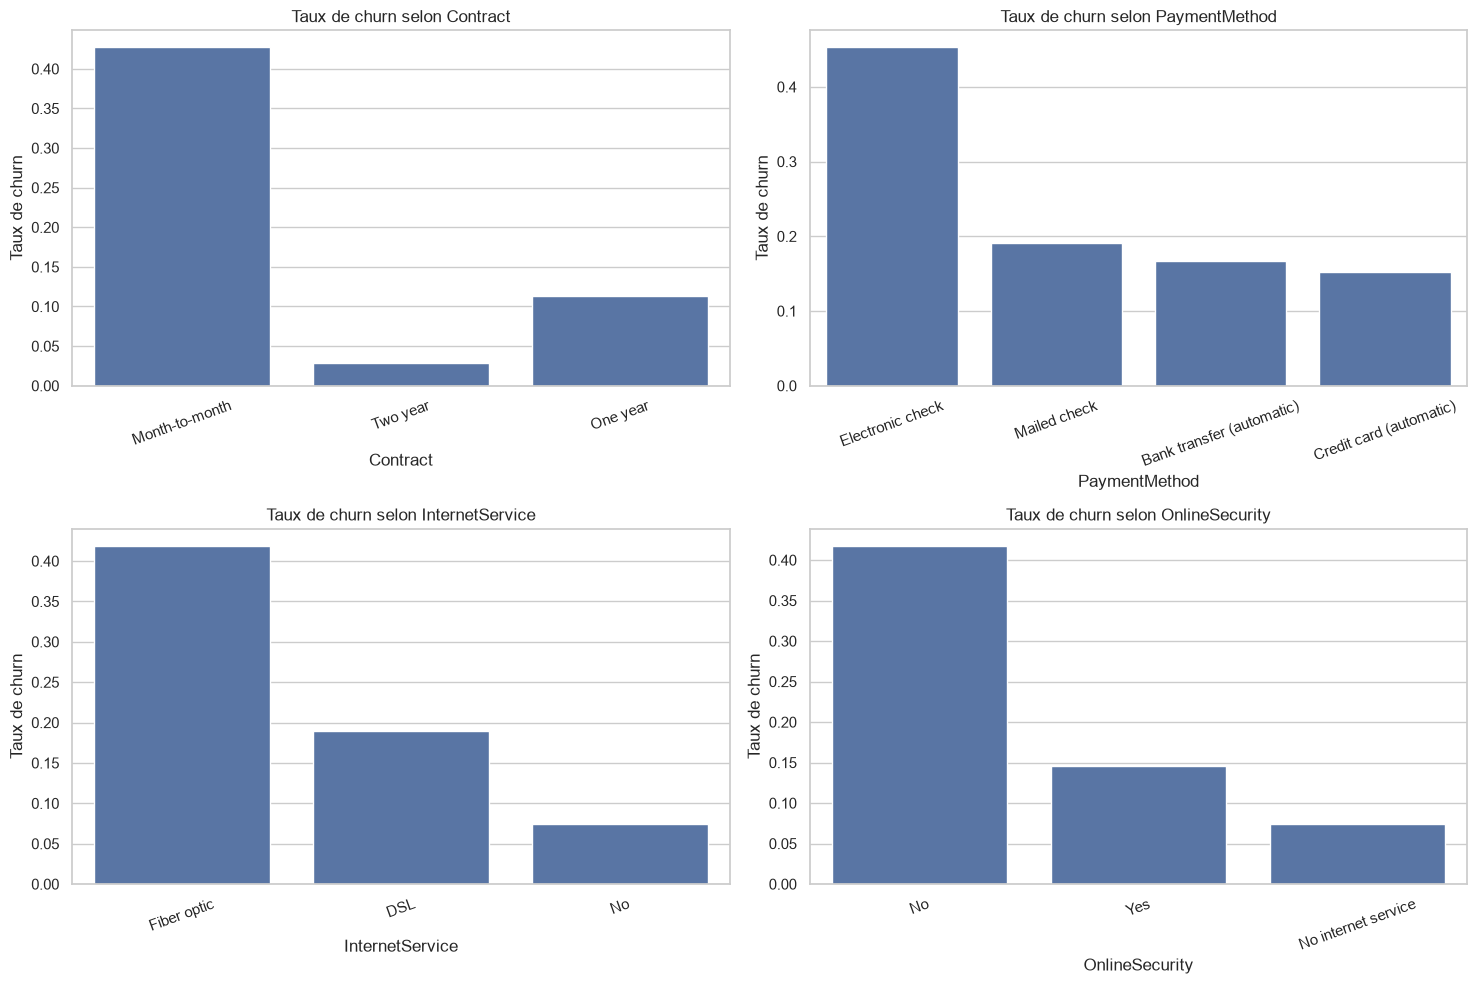

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_cols = ["Contract", "PaymentMethod", "InternetService", "OnlineSecurity"]

for ax, col in zip(axes.flat, plot_cols, strict=False):
    order = df_clean[col].value_counts().index
    sns.barplot(
        data=df_clean,
        x=col,
        y=df_clean["Churn"].eq("Yes").astype(int),
        order=order,
        estimator=np.mean,
        errorbar=None,
        ax=ax,
    )
    ax.set_title(f"Taux de churn selon {col}")
    ax.set_ylabel("Taux de churn")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 9. Analyse de survie — Kaplan-Meier

L'estimateur de Kaplan-Meier estime la probabilité de rester abonné au-delà d'un temps donné, en tenant compte des observations censurées.

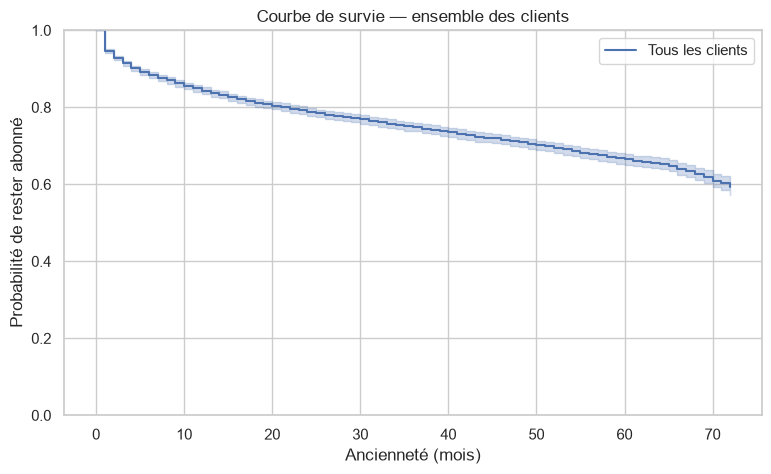

Probabilité de survie estimée à 72 mois : 59.28%
Médiane de survie : inf


In [20]:
kmf = KaplanMeierFitter()
kmf.fit(durations=duration, event_observed=event, label="Tous les clients")

fig, ax = plt.subplots(figsize=(9, 5))
kmf.plot_survival_function(ax=ax, ci_show=True)
ax.set_title("Courbe de survie — ensemble des clients")
ax.set_xlabel("Ancienneté (mois)")
ax.set_ylabel("Probabilité de rester abonné")
ax.set_ylim(0, 1)
plt.show()

survival_72 = float(kmf.predict(72))
print(f"Probabilité de survie estimée à 72 mois : {survival_72:.2%}")
print(f"Médiane de survie : {kmf.median_survival_time_}")

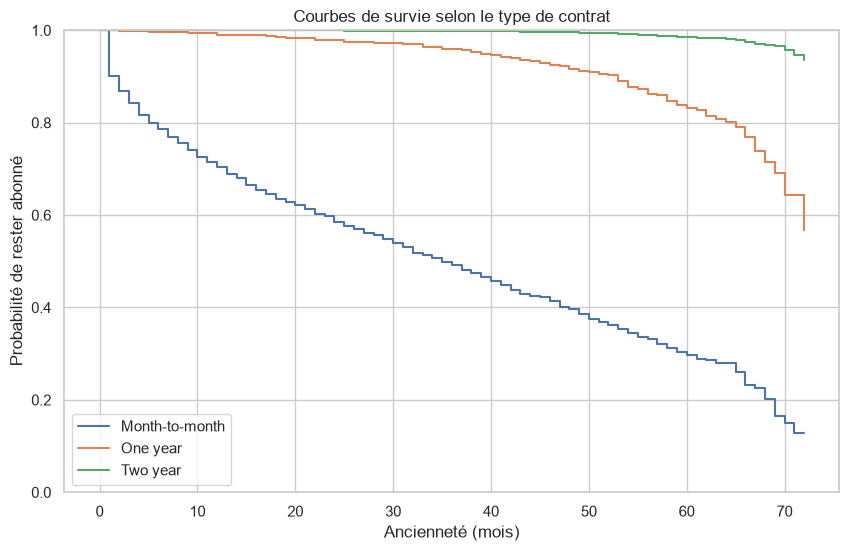

In [21]:
contract_kmf = {}

fig, ax = plt.subplots(figsize=(10, 6))
for contract in ["Month-to-month", "One year", "Two year"]:
    mask = df_clean["Contract"].eq(contract)
    fitter = KaplanMeierFitter()
    fitter.fit(
        durations=duration[mask.to_numpy()],
        event_observed=event[mask.to_numpy()],
        label=contract,
    )
    fitter.plot_survival_function(ax=ax, ci_show=False)
    contract_kmf[contract] = fitter

ax.set_title("Courbes de survie selon le type de contrat")
ax.set_xlabel("Ancienneté (mois)")
ax.set_ylabel("Probabilité de rester abonné")
ax.set_ylim(0, 1)
plt.show()

## 10. Tests Log-Rank

Le test Log-Rank compare les distributions de survie entre groupes. L'hypothèse nulle est que les groupes ont la même fonction de survie. Une petite p-value indique une différence statistiquement significative, sans démontrer une relation causale.

In [22]:
contract_groups = {
    name: df_clean["Contract"].eq(name).to_numpy()
    for name in ["Month-to-month", "One year", "Two year"]
}

logrank_global = multivariate_logrank_test(
    event_durations=duration,
    groups=df_clean["Contract"],
    event_observed=event,
)
print("Test Log-Rank global — Contract")
display(logrank_global.summary)

Test Log-Rank global — Contract


,test_statistic,p,-log2(p)
0,2352.872538,0.0,inf


In [23]:
pairwise_results = []

for group_a, group_b in combinations(contract_groups, 2):
    mask_a = contract_groups[group_a]
    mask_b = contract_groups[group_b]
    result = logrank_test(
        duration[mask_a],
        duration[mask_b],
        event_observed_A=event[mask_a],
        event_observed_B=event[mask_b],
    )
    pairwise_results.append({
        "groupe_1": group_a,
        "groupe_2": group_b,
        "chi2": result.test_statistic,
        "p_value": result.p_value,
    })

pairwise_df = pd.DataFrame(pairwise_results)
alpha = 0.05
number_of_tests = len(pairwise_df)
pairwise_df["p_value_bonferroni"] = (
    pairwise_df["p_value"] * number_of_tests
).clip(upper=1.0)
pairwise_df["significatif"] = pairwise_df["p_value_bonferroni"] < alpha

display(pairwise_df)

,groupe_1,groupe_2,chi2,p_value,p_value_bonferroni,significatif
0,Month-to-month,One year,926.064559,2.117327e-203,6.351980e-203,True
1,Month-to-month,Two year,1550.510307,0.000000e+00,0.000000e+00,True
2,One year,Two year,256.217767,1.145448e-57,3.436345e-57,True


## 11. Synthèse et limites

In [24]:
summary = {
    "clients": len(df_clean),
    "churn_observe": int(event.sum()),
    "observations_censurees": int((event == 0).sum()),
    "taux_churn": float(event.mean()),
    "anciennete_moyenne_mois": float(df_clean["tenure"].mean()),
    "anciennete_mediane_mois": float(df_clean["tenure"].median()),
    "survie_estimee_72_mois": survival_72,
}
display(pd.Series(summary, name="valeur").to_frame())

,valeur
clients,7043.000000
churn_observe,1869.000000
observations_censurees,5174.000000
taux_churn,0.265370
anciennete_moyenne_mois,32.371149
anciennete_mediane_mois,29.000000
survie_estimee_72_mois,0.592790


### Principaux constats

- Le dataset contient **7 043 clients** et 21 variables.
- Les 11 valeurs manquantes de `TotalCharges` concernent des clients avec `tenure = 0` ; elles ont été remplacées par `0.0`.
- Le churn observé représente environ **26,54 %** des clients ; les autres observations sont censurées à droite.
- Les clients ayant résilié présentent une ancienneté observée plus faible que les clients censurés.
- Le taux de churn est nettement plus élevé pour les contrats mensuels que pour les contrats d'un ou deux ans.
- Les courbes de Kaplan-Meier permettent de comparer les probabilités de maintien de l'abonnement dans le temps.
- Le test Log-Rank global et les comparaisons deux à deux évaluent si les différences de survie entre contrats sont statistiquement significatives.

### Limites d'interprétation

1. Les associations observées ne démontrent pas de causalité.
2. La censure doit être prise en compte : `Churn = No` ne signifie pas que le client restera abonné indéfiniment.
3. Les résultats dépendent de la période d'observation et de la qualité des données.
4. Les analyses exploratoires ne remplacent pas l'évaluation d'un modèle prédictif.

### Conclusion

Cette exploration confirme que le dataset est exploitable pour une analyse de survie après traitement des valeurs vides de `TotalCharges`. La variable `tenure` représente la durée observée et `Churn` indique si l'événement de résiliation a été observé. Les résultats et variables étudiés constituent une base pour les étapes suivantes de modélisation de survie avec Deep Learning.